<a href="https://colab.research.google.com/github/SOMUREX/AI-RESUME-SCREENER/blob/main/data%20analysis%20ml.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Breast Cancer Wisconsin - Exploratory Data Analysis
This notebook performs an exploratory data analysis on the Breast Cancer Wisconsin dataset.

In [ ]:
import zipfile
import os

zip_path = '/content/breast+cancer+wisconsin+original.zip'
extract_path = '/content/breast_cancer_data'

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_path)

print("Extracted files:")
for root, dirs, files in os.walk(extract_path):
    for file in files:
        print(os.path.join(root, file))

In [ ]:
import os
import pandas as pd

# Let's find all file paths in the extracted folder
extracted_files = []
for root, dirs, files in os.walk('/content/breast_cancer_data'):
    for file in files:
        extracted_files.append(os.path.join(root, file))

print("Available extracted files:", extracted_files)

# Typically, this dataset contains 'breast-cancer-wisconsin.data' or similar
data_file = None
for f in extracted_files:
    if f.endswith('.data') or f.endswith('.csv') or 'wisconsin' in f.lower():
        data_file = f
        break

if data_file:
    print(f"Loading data from: {data_file}")
    # The original Wisconsin breast cancer dataset does not have headers
    # Common columns: Sample code number, Clump Thickness, Uniformity of Cell Size,
    # Uniformity of Cell Shape, Marginal Adhesion, Single Epithelial Cell Size,
    # Bare Nuclei, Bland Chromatin, Normal Nucleoli, Mitoses, Class
    column_names = [
        'Sample_Code_Number', 'Clump_Thickness', 'Uniformity_of_Cell_Size',
        'Uniformity_of_Cell_Shape', 'Marginal_Adhesion', 'Single_Epithelial_Cell_Size',
        'Bare_Nuclei', 'Bland_Chromatin', 'Normal_Nucleoli', 'Mitoses', 'Class'
    ]
    df = pd.read_csv(data_file, names=column_names, na_values='?')
    display(df.head())
else:
    print("Could not automatically determine the data file. Please inspect the printed file list.")

In [3]:
import os
import zipfile
import pandas as pd

zip_path = '/content/breast+cancer+wisconsin+original.zip'
extract_path = '/content/breast_cancer_data'

# Extract zip if not already done
if not os.path.exists(extract_path) and os.path.exists(zip_path):
    with zipfile.ZipFile(zip_path, 'r') as zip_ref:
        zip_ref.extractall(extract_path)

# Find the dataset file
extracted_files = []
for root, dirs, files in os.walk(extract_path):
    for file in files:
        extracted_files.append(os.path.join(root, file))

data_file = next((f for f in extracted_files if f.endswith('.data') or 'wisconsin' in f.lower()), None)

column_names = [
    'Sample_Code_Number', 'Clump_Thickness', 'Uniformity_of_Cell_Size',
    'Uniformity_of_Cell_Shape', 'Marginal_Adhesion', 'Single_Epithelial_Cell_Size',
    'Bare_Nuclei', 'Bland_Chromatin', 'Normal_Nucleoli', 'Mitoses', 'Class'
]

if data_file:
    df = pd.read_csv(data_file, names=column_names, na_values='?')

    # Check for missing values in the dataset
    missing_values = df.isnull().sum()
    print("Missing values per column:")
    print(missing_values)

    # Also let's inspect the data types and total records
    print("\nDataset Info:")
    df.info()
else:
    print("Could not find the dataset file. Please check if the ZIP file is present at:", zip_path)

Missing values per column:
Sample_Code_Number              0
Clump_Thickness                 0
Uniformity_of_Cell_Size         0
Uniformity_of_Cell_Shape        0
Marginal_Adhesion               0
Single_Epithelial_Cell_Size     0
Bare_Nuclei                    16
Bland_Chromatin                 0
Normal_Nucleoli                 0
Mitoses                         0
Class                           0
dtype: int64

Dataset Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 699 entries, 0 to 698
Data columns (total 11 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   Sample_Code_Number           699 non-null    int64  
 1   Clump_Thickness              699 non-null    int64  
 2   Uniformity_of_Cell_Size      699 non-null    int64  
 3   Uniformity_of_Cell_Shape     699 non-null    int64  
 4   Marginal_Adhesion            699 non-null    int64  
 5   Single_Epithelial_Cell_Size  699 non-null    int64  
 6

In [4]:
# Calculate the median of the Bare_Nuclei column
bare_nuclei_median = df['Bare_Nuclei'].median()
print(f"Median of Bare_Nuclei: {bare_nuclei_median}")

# Fill missing values in-place with the median
df['Bare_Nuclei'] = df['Bare_Nuclei'].fillna(bare_nuclei_median)

# Verify that there are no missing values left
print("\nMissing values after imputation:")
print(df.isnull().sum())

Median of Bare_Nuclei: 1.0

Missing values after imputation:
Sample_Code_Number             0
Clump_Thickness                0
Uniformity_of_Cell_Size        0
Uniformity_of_Cell_Shape       0
Marginal_Adhesion              0
Single_Epithelial_Cell_Size    0
Bare_Nuclei                    0
Bland_Chromatin                0
Normal_Nucleoli                0
Mitoses                        0
Class                          0
dtype: int64


In [5]:
# Drop the Sample_Code_Number column
if 'Sample_Code_Number' in df.columns:
    df = df.drop(columns=['Sample_Code_Number'])
    print("Sample_Code_Number column dropped successfully.")
else:
    print("Sample_Code_Number column not found or already dropped.")

# Display the updated columns and the first few rows
print("Remaining columns:", list(df.columns))
display(df.head())

Sample_Code_Number column dropped successfully.
Remaining columns: ['Clump_Thickness', 'Uniformity_of_Cell_Size', 'Uniformity_of_Cell_Shape', 'Marginal_Adhesion', 'Single_Epithelial_Cell_Size', 'Bare_Nuclei', 'Bland_Chromatin', 'Normal_Nucleoli', 'Mitoses', 'Class']


,Clump_Thickness,Uniformity_of_Cell_Size,Uniformity_of_Cell_Shape,Marginal_Adhesion,Single_Epithelial_Cell_Size,Bare_Nuclei,Bland_Chromatin,Normal_Nucleoli,Mitoses,Class
0,5,1,1,1,2,1.0,3,1,1,2
1,5,4,4,5,7,10.0,3,2,1,2
2,3,1,1,1,2,2.0,3,1,1,2
3,6,8,8,1,3,4.0,3,7,1,2
4,4,1,1,3,2,1.0,3,1,1,2


In [6]:
# Map Class column: 2 -> 0 (benign), 4 -> 1 (malignant)
df['Class'] = df['Class'].map({2: 0, 4: 1})

# Display unique values to verify the mapping and check the first few rows
print("Unique values in Class column:", df['Class'].unique())
display(df.head())

Unique values in Class column: [0 1]


,Clump_Thickness,Uniformity_of_Cell_Size,Uniformity_of_Cell_Shape,Marginal_Adhesion,Single_Epithelial_Cell_Size,Bare_Nuclei,Bland_Chromatin,Normal_Nucleoli,Mitoses,Class
0,5,1,1,1,2,1.0,3,1,1,0
1,5,4,4,5,7,10.0,3,2,1,0
2,3,1,1,1,2,2.0,3,1,1,0
3,6,8,8,1,3,4.0,3,7,1,0
4,4,1,1,3,2,1.0,3,1,1,0


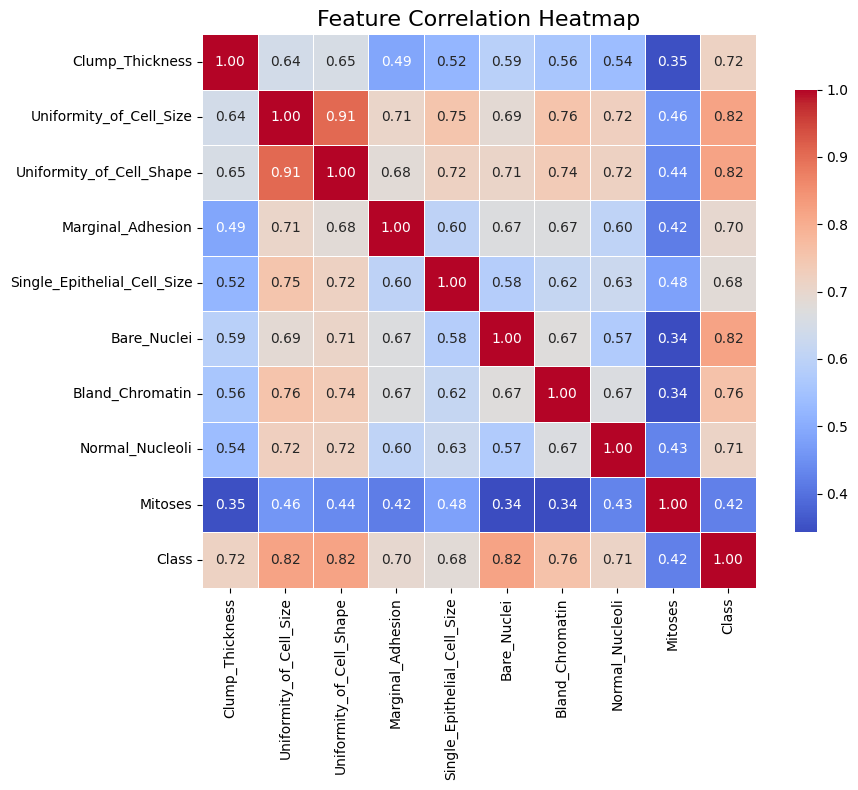

In [7]:
import matplotlib.pyplot as plt
import seaborn as sns

# Calculate the correlation matrix
corr_matrix = df.corr()

# Set up the matplotlib figure
plt.figure(figsize=(10, 8))

# Generate a heatmap
sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".2f",
    cmap='coolwarm',
    square=True,
    linewidths=0.5,
    cbar_kws={"shrink": .8}
)

plt.title('Feature Correlation Heatmap', fontsize=16)
plt.tight_layout()
plt.show()

In [8]:
from sklearn.model_selection import train_test_split

# Separate features (X) and target (y)
X = df.drop(columns=['Class'])
y = df['Class']

# Split the dataset into 80% training and 20% testing sets
# We use stratify=y to maintain class proportions across train/test splits
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Verify the split shapes
print(f"Training features shape: {X_train.shape}")
print(f"Testing features shape: {X_test.shape}")
print(f"Training target class ratio:\n{y_train.value_counts(normalize=True)}")
print(f"Testing target class ratio:\n{y_test.value_counts(normalize=True)}")

Training features shape: (559, 9)
Testing features shape: (140, 9)
Training target class ratio:
Class
0    0.654741
1    0.345259
Name: proportion, dtype: float64
Testing target class ratio:
Class
0    0.657143
1    0.342857
Name: proportion, dtype: float64


In [9]:
from sklearn.linear_model import LogisticRegression

# Initialize the Logistic Regression model
# We increase max_iter to ensure convergence during training
log_reg = LogisticRegression(random_state=42, max_iter=1000)

# Train the model
log_reg.fit(X_train, y_train)

print("Logistic Regression model has been trained successfully!")

Logistic Regression model has been trained successfully!


Accuracy on Testing Set: 0.9500

Classification Report:
               precision    recall  f1-score   support

   Benign (0)       0.96      0.97      0.96        92
Malignant (1)       0.94      0.92      0.93        48

     accuracy                           0.95       140
    macro avg       0.95      0.94      0.94       140
 weighted avg       0.95      0.95      0.95       140



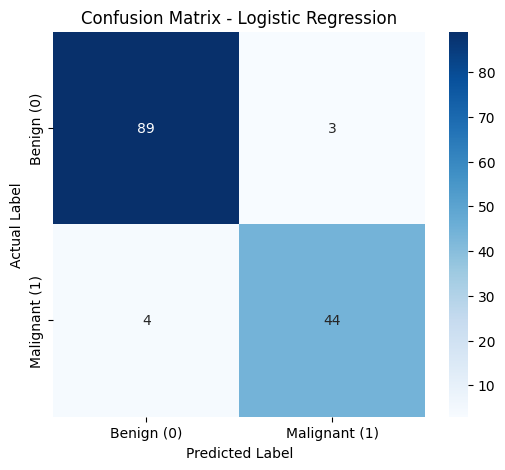

In [10]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

# Make predictions on the testing set
y_pred = log_reg.predict(X_test)

# Calculate accuracy
accuracy = accuracy_score(y_test, y_pred)
print(f"Accuracy on Testing Set: {accuracy:.4f}\n")

# Print classification report
print("Classification Report:")
print(classification_report(y_test, y_pred, target_names=['Benign (0)', 'Malignant (1)']))

# Compute and plot confusion matrix
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Benign (0)', 'Malignant (1)'],
    yticklabels=['Benign (0)', 'Malignant (1)']
)
plt.title('Confusion Matrix - Logistic Regression')
plt.ylabel('Actual Label')
plt.xlabel('Predicted Label')
plt.show()

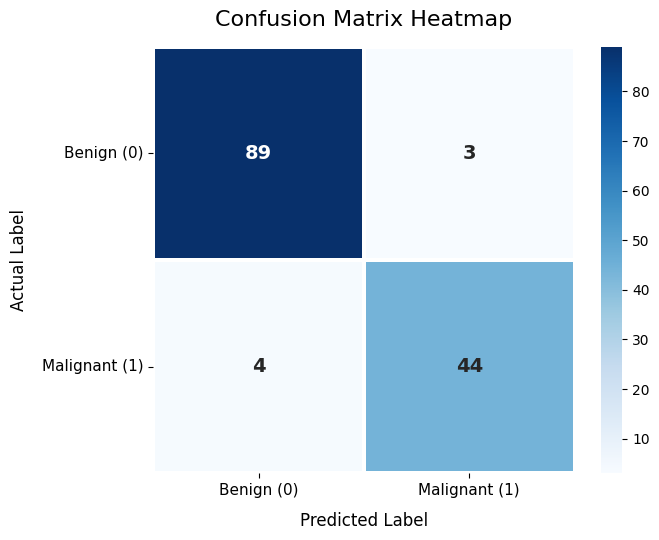

In [11]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# Compute the confusion matrix using the test targets and predictions
cm = confusion_matrix(y_test, y_pred)

# Create a styled heatmap plot
plt.figure(figsize=(7, 5.5))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    linewidths=1.5,
    linecolor='white',
    xticklabels=['Benign (0)', 'Malignant (1)'],
    yticklabels=['Benign (0)', 'Malignant (1)'],
    cbar=True,
    annot_kws={'size': 14, 'weight': 'bold'}
)

# Add details and labels
plt.title('Confusion Matrix Heatmap', fontsize=16, pad=15)
plt.xlabel('Predicted Label', fontsize=12, labelpad=10)
plt.ylabel('Actual Label', fontsize=12, labelpad=10)
plt.xticks(fontsize=11)
plt.yticks(fontsize=11, rotation=0)
plt.tight_layout()
plt.show()

Random Forest Accuracy on Testing Set: 0.9500

Classification Report (Random Forest):
               precision    recall  f1-score   support

   Benign (0)       0.97      0.96      0.96        92
Malignant (1)       0.92      0.94      0.93        48

     accuracy                           0.95       140
    macro avg       0.94      0.95      0.94       140
 weighted avg       0.95      0.95      0.95       140



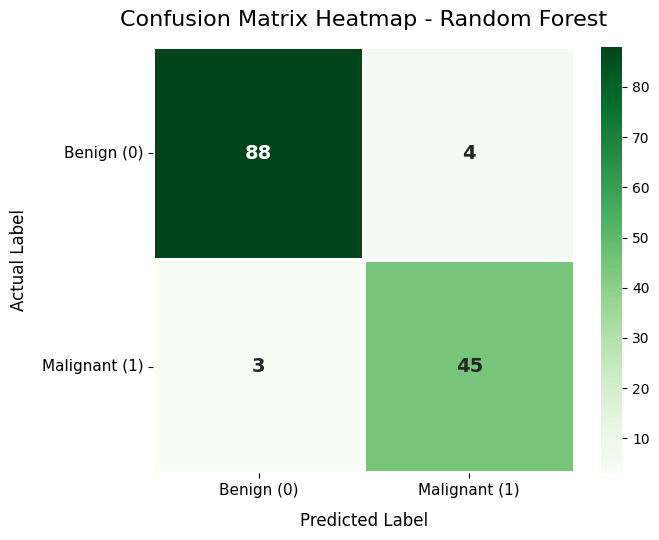

In [12]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

# Initialize the Random Forest model
rf_clf = RandomForestClassifier(random_state=42, n_estimators=100)

# Train the model
rf_clf.fit(X_train, y_train)

# Predict on test data
y_pred_rf = rf_clf.predict(X_test)

# Evaluate and display performance
accuracy_rf = accuracy_score(y_test, y_pred_rf)
print(f"Random Forest Accuracy on Testing Set: {accuracy_rf:.4f}\n")
print("Classification Report (Random Forest):")
print(classification_report(y_test, y_pred_rf, target_names=['Benign (0)', 'Malignant (1)']))

# Compute and plot confusion matrix
cm_rf = confusion_matrix(y_test, y_pred_rf)
plt.figure(figsize=(7, 5.5))
sns.heatmap(
    cm_rf,
    annot=True,
    fmt='d',
    cmap='Greens',
    linewidths=1.5,
    linecolor='white',
    xticklabels=['Benign (0)', 'Malignant (1)'],
    yticklabels=['Benign (0)', 'Malignant (1)'],
    cbar=True,
    annot_kws={'size': 14, 'weight': 'bold'}
)
plt.title('Confusion Matrix Heatmap - Random Forest', fontsize=16, pad=15)
plt.xlabel('Predicted Label', fontsize=12, labelpad=10)
plt.ylabel('Actual Label', fontsize=12, labelpad=10)
plt.xticks(fontsize=11)
plt.yticks(fontsize=11, rotation=0)
plt.tight_layout()
plt.show()